In [1]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import torch
from torch import nn

import numpy as np
import normflows as nf

import tqdm

import matplotlib.pyplot as plt

In [2]:
import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\dev\\scripts\\..\\src']


In [ ]:
def sign_nonzero(x):
    # Need a sign function where sign(0) = 1, otherwise when transforming 3d vectors to spherical coords
    # the vectors [1, 0, 0] and [-1, 0, 0] get the same angle
    return torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))


def spherical_from_3d(v: torch.Tensor, as_lat: bool = True):
    """
    Computes the polar and azimuth angle of the given 3d vector.
    
    Arguments:
        v (torch.Tensor): tensor of vectors. requires v.shape[-1] ==  3
        as_lat (bool, optional): if True, the equator will have a polar angle of 0, otherwise v = (0, 0, 1) will have 0 polar angle

    """
    if type(v) is np.ndarray:
        v = torch.from_numpy(v)

    if not torch.is_floating_point(v):
        v = v.type(torch.float32)

    torch._assert(v.shape[-1] == 3, "Can only convert torch tensors with 3 elements in last dimension")

    v = torch.nn.functional.normalize(v, dim = -1)

    polar = torch.asin(v[..., 2]) if as_lat else torch.acos(v[..., 2])
    x = v[..., 0]
    y = v[..., 1]

    
    azimuth = torch.where((x != 0) | (y != 0), torch.acos(x / (x.square() + y.square()).sqrt()) * sign_nonzero(y), 0)

    return torch.stack((azimuth, polar), dim = -1)

def spherical_to_3d(v: torch.Tensor, as_lat: bool = True):
    """
    Computes a direction from a given azimuth and polar angle
    
    Arguments:
        v (torch.Tensor): tensor of angles. requires v.shape[-1] == 2, with v[..., 0] being the azimuth and v[..., 1] he polar angle
        as_lat (bool, optional): if True, the equator will have a polar angle of 0, otherwise v = (0, 0, 1) will have 0 polar angle

    """
    if type(v) is np.ndarray:
        v = torch.from_numpy(v)

    if not torch.is_floating_point(v):
        v = v.type(torch.float32)

    torch._assert(v.shape[-1] == 2, "Can only convert torch tensors with 3 elements in last dimension")

    polar = v[..., 1]
    z =                 torch.sin(polar) if as_lat else torch.cos(polar)
    xy_norm_factor =    torch.cos(polar) if as_lat else torch.sin(polar)

    azimuth = v[..., 0]
    x = torch.cos(azimuth) * xy_norm_factor
    y = torch.sin(azimuth) * xy_norm_factor

    return torch.stack((x, y, z), dim = -1)


def uniform_sphere(num_samples, device='cpu'):
    t = torch.randn((num_samples, 3), device = device)
    return spherical_from_3d(t)

In [93]:
def von_mises_fisher_pdf(v, mean_dir, kappa):
    if kappa == 0:
        return torch.full_like(input=v, fill_value=1 / (4 * torch.pi))

    dots = (v * mean_dir).sum(dim=-1)
    exp_term = torch.exp(kappa * dots)

    # For p = 3, formula taken from wikipedia https://en.wikipedia.org/wiki/Von_Mises%E2%80%93Fisher_distribution
    denom = 2 * torch.pi * (torch.exp(kappa) - torch.exp(-kappa))
    constant = kappa / denom

    return constant * exp_term

def rotation_matrix_from_a_to_b(a, b):
    a = torch.nn.functional.normalize(a, dim=-1)
    b = torch.nn.functional.normalize(b, dim=-1)

    v = torch.cross(a, b, dim=-1)  # rotation axis
    c = torch.sum(a * b, dim=-1, keepdim=True)  # cosine

    # skew-symmetric cross-product matrix of v
    vx = torch.zeros(a.shape[0], 3, 3, device=a.device)
    vx[:, 0, 1] = -v[:, 2]
    vx[:, 0, 2] =  v[:, 1]
    vx[:, 1, 0] =  v[:, 2]
    vx[:, 1, 2] = -v[:, 0]
    vx[:, 2, 0] = -v[:, 1]
    vx[:, 2, 1] =  v[:, 0]

    I = torch.eye(3, device=a.device).unsqueeze(0).expand_as(vx)
    vx2 = vx @ vx

    # Rodrigues’ rotation formula
    R = I + vx + vx2 * (1 / (1 + c))
    return R

def von_mises_fisher_sample(num_samples, mean_dir, kappa):
    V = torch.rand(num_samples) * torch.pi * 2
    # V = torch.full_like(V, fill_value=torch.pi / 2)

    Eta = torch.rand(num_samples)
    W = 1 + 1 / kappa * torch.log(Eta + (1 - Eta) * torch.exp(-2 * kappa))

    angles = torch.stack((V, torch.acos(W)), dim = -1)
    
    vecs = spherical_to_3d(angles)

    R = rotation_matrix_from_a_to_b(torch.tensor([[0.,0.,1.]]), mean_dir.unsqueeze(0))
    rotated = (R @ vecs.unsqueeze(-1)).squeeze(-1)

    return spherical_from_3d(rotated)
    """
    TODO transform the vecs.
    if mean_dir = [0, 0, 1] then we don't want to transform
        -> [0, 0, 1] should be mapped to mean_dir
    
    get some tangent space
    
    """


def sample_vMF(mu, kappa, n_samples):
    """
    Sample from 3D von-Mises-Fisher distribution.
    
    Args:
        mu: tensor of shape (3,), mean direction (will be normalized).
        kappa: scalar concentration > 0
        n_samples: number of samples
    
    Returns:
        samples: tensor of shape (n_samples, 3)
    """
    device = mu.device
    mu = mu / mu.norm()  # ensure unit vector

    # Step 1: sample w
    u = torch.rand(n_samples, device=device)
    w = 1 + (1.0 / kappa) * torch.log(u + (1 - u) * torch.exp(-2 * kappa))

    # Step 2: sample v ~ uniform on circle orthogonal to mu
    phi = 2 * torch.pi * torch.rand(n_samples, device=device)
    v = torch.stack([torch.cos(phi), torch.sin(phi)], dim=-1)  # (n_samples, 2)

    # Build orthonormal basis around mu
    # (same idea as tangent space construction earlier)
    ref = torch.tensor([0.0, 1.0, 0.0], device=device)
    if torch.allclose(mu, ref):  # avoid collinearity
        ref = torch.tensor([1.0, 0.0, 0.0], device=device)
    t1 = ref - torch.dot(mu, ref) * mu
    t1 = t1 / t1.norm()
    t2 = torch.cross(mu, t1)
    T = torch.stack([t1, t2], dim=-1)  # (3, 2)

    # Step 3: construct samples
    ortho = v @ T.T  # (n_samples, 3)
    samples = (w.unsqueeze(-1) * mu + torch.sqrt(1 - w**2).unsqueeze(-1) * ortho)

    return samples

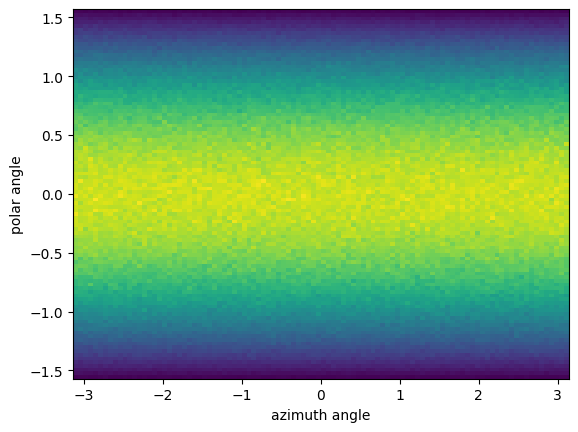

In [121]:
unnorm_mean_dir = torch.tensor([0, 1, 0], dtype=torch.float32)
mean_dir = torch.nn.functional.normalize(unnorm_mean_dir, dim = 0)
kappa = torch.tensor([0.0001], dtype=torch.float32)

#samples = von_mises_fisher_sample(1000, mean_dir, kappa = kappa)
# print(samples)
# samples = sample_vMF(mu = mean_dir, kappa = kappa, n_samples=10000)
samples = uniform_sphere(10000000, device='cpu')

plt.hist2d(samples[..., 0], samples[..., 1], bins = 100, range = [[-np.pi, np.pi], [-np.pi / 2, np.pi / 2]])
plt.xlabel("azimuth angle")
plt.ylabel("polar angle")
plt.show()

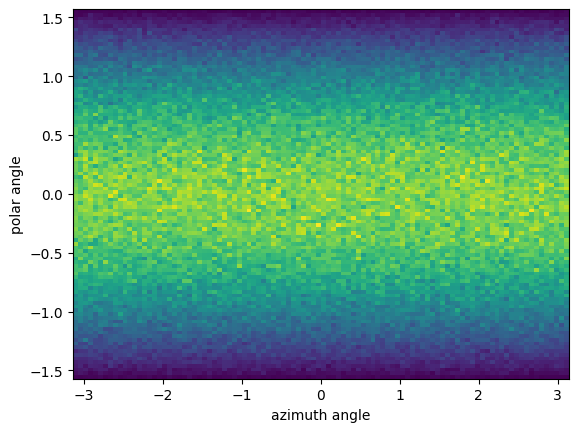

In [5]:
t = torch.randn((1000000, 3))
spherical = spherical_from_3d(t)

plt.hist2d(spherical[..., 0], spherical[..., 1], bins = 100, range = [[-np.pi, np.pi], [-np.pi / 2, np.pi / 2]])
plt.xlabel("azimuth angle")
plt.ylabel("polar angle")
plt.show()

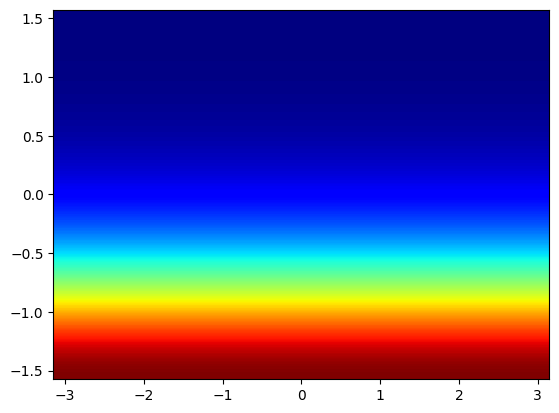

In [64]:
grid_size = 500

xx, yy = torch.meshgrid(torch.linspace(-np.pi, np.pi, grid_size), torch.linspace(-np.pi / 2, np.pi / 2, grid_size))

v = torch.stack((xx, yy), dim = -1)
dirs = spherical_to_3d(v)

unnorm_mean_dir = torch.tensor([0, 0, -1], dtype=torch.float32)
mean_dir = torch.nn.functional.normalize(unnorm_mean_dir, dim = 0)
kappa = torch.tensor([2])
weight = 1.0

unnorm_mean_dir2 = torch.tensor([1, -4, 3], dtype=torch.float32)
mean_dir2 = torch.nn.functional.normalize(unnorm_mean_dir2, dim = 0)
kappa2 = torch.tensor([10])
weight2 = 0.0


von_mises1 = von_mises_fisher_pdf(dirs, mean_dir=mean_dir, kappa=kappa)
von_mises2 = von_mises_fisher_pdf(dirs, mean_dir=mean_dir2, kappa=kappa2)

von_mises = weight * von_mises1 + weight2 * von_mises2

plt.pcolormesh(xx, yy, von_mises, cmap='jet')